# 03 — Model Training & Evaluation

Pipeline stage 3 of 5.

Loads `cleaned_reports.pkl`, splits stratified 80/20, trains 3 baselines
(Logistic Regression, Multinomial Naive Bayes, Linear SVM), compares them,
and saves the best model.

Saves:
- `artifacts/cti_text_classifier.joblib`
- `artifacts/model_results.csv`


In [1]:

# ---------------------------------------------------------------------------
# Bootstrap — paths, imports, global config
# ---------------------------------------------------------------------------
import os
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(r"D:\Projects\done\thesis\ctc_ectd")
SCRIPTS_DIR  = PROJECT_ROOT / "scripts"
UPLOAD_DIR   = PROJECT_ROOT / "uploads"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

for d in (SCRIPTS_DIR, UPLOAD_DIR, ARTIFACT_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

print("PROJECT_ROOT :", PROJECT_ROOT)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("ARTIFACT_DIR :", ARTIFACT_DIR)
print("UPLOAD_DIR   :", UPLOAD_DIR)


PROJECT_ROOT : D:\Projects\done\thesis\ctc_ectd
PROCESSED_DIR: D:\Projects\done\thesis\ctc_ectd\data\processed
ARTIFACT_DIR : D:\Projects\done\thesis\ctc_ectd\artifacts
UPLOAD_DIR   : D:\Projects\done\thesis\ctc_ectd\uploads


In [2]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay,
)
import joblib

payload = pd.read_pickle(PROCESSED_DIR / "cleaned_reports.pkl")
df = payload["df"]
LABEL_COL = payload["LABEL_COL"]
print("Loaded:", df.shape, "| LABEL_COL:", LABEL_COL)


Loaded: (10000, 18) | LABEL_COL: category


## 1. Stratified split

In [3]:

X = df["model_text"]
y = df[LABEL_COL]
cc = y.value_counts()
strat = y.nunique() > 1 and cc.min() >= 2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE,
    stratify=y if strat else None,
)
print("Train:", len(X_train), "| Test:", len(X_test),
      "| Classes:", y_train.nunique())


Train: 8000 | Test: 2000 | Classes: 10


## 2. Define baselines

In [4]:

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000,
                                  ngram_range=(1, 2),
                                  stop_words="english",
                                  sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=2000,
                                   class_weight="balanced",
                                   random_state=RANDOM_STATE)),
    ]),
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000,
                                  ngram_range=(1, 2),
                                  stop_words="english")),
        ("clf", MultinomialNB()),
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000,
                                  ngram_range=(1, 2),
                                  stop_words="english",
                                  sublinear_tf=True)),
        ("clf", LinearSVC(class_weight="balanced",
                          random_state=RANDOM_STATE)),
    ]),
}


## 3. Train + evaluate

In [5]:

results = []
trained = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    p, r, f, _ = precision_recall_fscore_support(
        y_test, preds, average="weighted", zero_division=0)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Weighted Precision": p,
        "Weighted Recall": r,
        "Weighted F1": f,
    })
    trained[name] = model

results_df = (pd.DataFrame(results)
              .sort_values("Weighted F1", ascending=False)
              .reset_index(drop=True))
display(results_df.round(4))


Training Logistic Regression...
Training Multinomial Naive Bayes...
Training Linear SVM...


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Multinomial Naive Bayes,1.0,1.0,1.0,1.0
2,Linear SVM,1.0,1.0,1.0,1.0


## 4. Detailed report + confusion matrix for the best model

Best baseline: Logistic Regression
                  precision    recall  f1-score   support

          Botnet       1.00      1.00      1.00       197
Credential Theft       1.00      1.00      1.00       199
            DDoS       1.00      1.00      1.00       205
     Data Breach       1.00      1.00      1.00       198
  Insider Threat       1.00      1.00      1.00       187
         Malware       1.00      1.00      1.00       197
        Phishing       1.00      1.00      1.00       197
      Ransomware       1.00      1.00      1.00       208
   Vulnerability       1.00      1.00      1.00       204
      Web Attack       1.00      1.00      1.00       208

        accuracy                           1.00      2000
       macro avg       1.00      1.00      1.00      2000
    weighted avg       1.00      1.00      1.00      2000



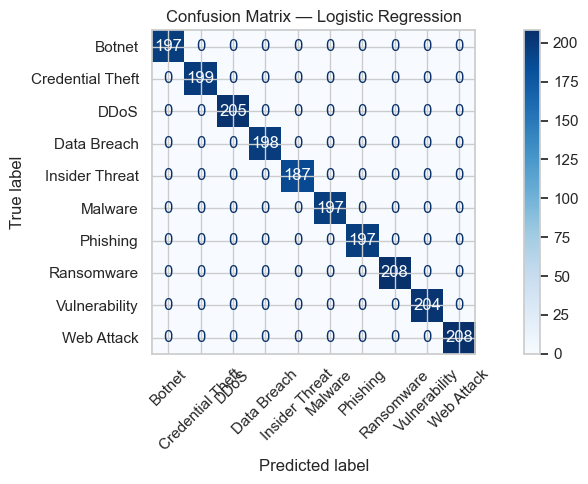

In [6]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained[best_model_name]
y_pred = best_model.predict(X_test)

print("Best baseline:", best_model_name)
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=45, cmap="Blues")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout(); plt.show()


## 5. Save model + results

In [7]:

joblib.dump(best_model, ARTIFACT_DIR / "cti_text_classifier.joblib")
results_df.to_csv(ARTIFACT_DIR / "model_results.csv", index=False)

print("Saved:", ARTIFACT_DIR / "cti_text_classifier.joblib")
print("Saved:", ARTIFACT_DIR / "model_results.csv")
print("Selected model:", best_model_name)


Saved: D:\Projects\done\thesis\ctc_ectd\artifacts\cti_text_classifier.joblib
Saved: D:\Projects\done\thesis\ctc_ectd\artifacts\model_results.csv
Selected model: Logistic Regression
